In [1]:
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
print("Ready!")

Ready!


In [2]:
trends = pd.read_csv("data/raw/google_trends_2004_present.csv", parse_dates=["Time"])
trends.head()

,Time,Hannah Montana,Wizards of Waverly Place,iCarly,That's So Raven,Lizzie McGuire
0,2004-01-01,0,0,0,3,8
1,2004-02-01,0,0,0,2,8
2,2004-03-01,0,0,0,2,6
3,2004-04-01,0,0,0,2,6
4,2004-05-01,0,0,0,2,5


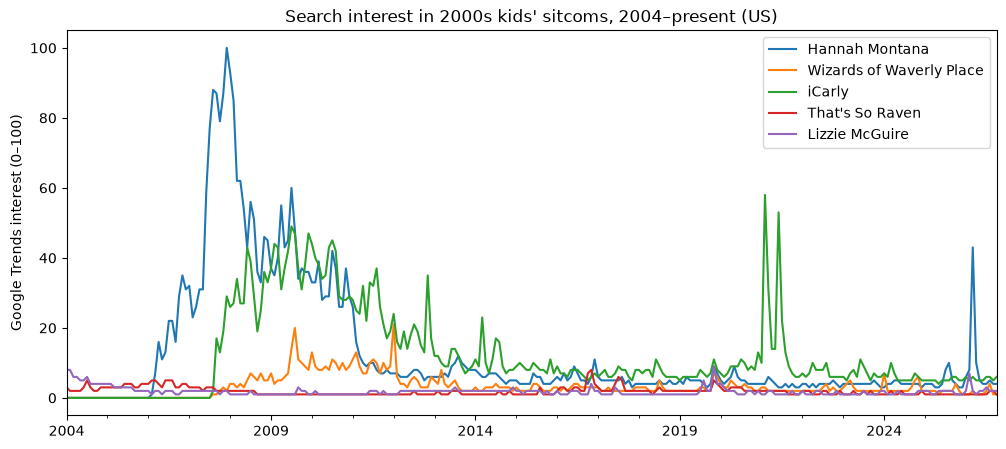

In [3]:
trends.plot(x="Time", figsize=(12, 5), title="Search interest in 2000s kids' sitcoms, 2004–present (US)")
plt.ylabel("Google Trends interest (0–100)")
plt.xlabel("")
plt.show()

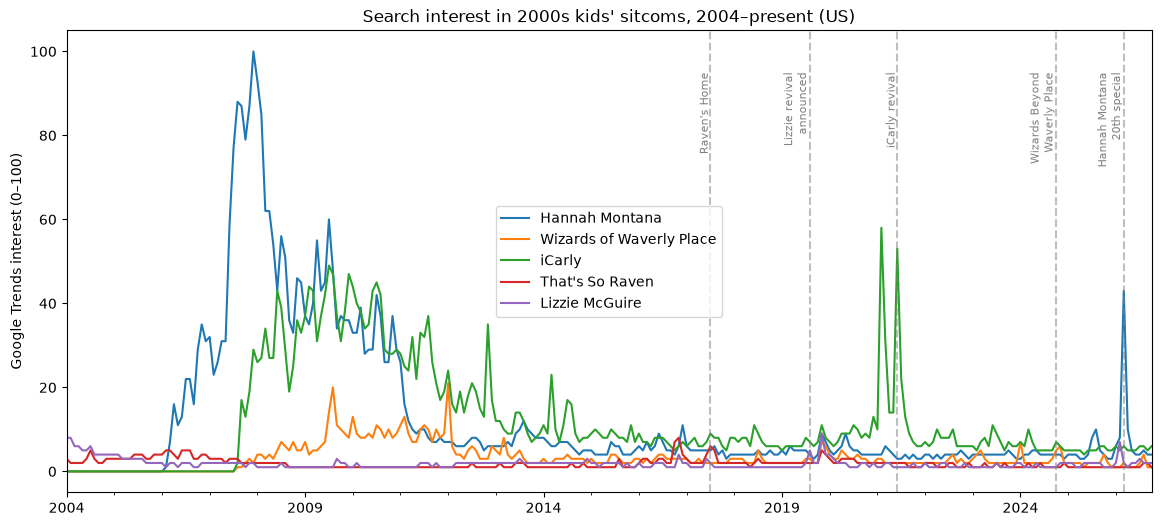

In [4]:
events = {
    "Raven's Home": "2017-07-01",
    "Lizzie revival\nannounced": "2019-08-01",
    "iCarly revival": "2021-06-01",
    "Wizards Beyond\nWaverly Place": "2024-10-01",
    "Hannah Montana\n20th special": "2026-03-01",
}

ax = trends.plot(x="Time", figsize=(14, 6), title="Search interest in 2000s kids' sitcoms, 2004–present (US)")
for label, date in events.items():
    d = pd.to_datetime(date)
    ax.axvline(d, color="gray", linestyle="--", alpha=0.5)
    ax.text(d, 95, label, rotation=90, va="top", ha="right", fontsize=8, color="gray")

plt.ylabel("Google Trends interest (0–100)")
plt.xlabel("")
plt.savefig("charts/hero_chart_v1.png", dpi=200, bbox_inches="tight")
plt.show()

In [5]:
data = trends.set_index("Time")

revivals = [
    ("That's So Raven", "Raven's Home", "2017-07-01"),
    ("Lizzie McGuire", "Lizzie revival announced", "2019-08-01"),
    ("iCarly", "iCarly revival", "2021-06-01"),
    ("Wizards of Waverly Place", "Wizards Beyond Waverly Place", "2024-10-01"),
    ("Hannah Montana", "Hannah Montana 20th special", "2026-03-01"),
]

rows = []
for show, label, date in revivals:
    d = pd.to_datetime(date)
    s = data[show]
    baseline = s[d - pd.DateOffset(months=12) : d - pd.DateOffset(months=1)].median()
    window = s[d - pd.DateOffset(months=2) : d + pd.DateOffset(months=2)]
    peak = window.max()
    peak_month = window.idxmax()
    after = s[peak_month:]
    back_to_normal = after[after <= baseline * 1.5]
    months_to_fade = (back_to_normal.index[0].to_period("M") - peak_month.to_period("M")).n

    rows.append({
        "event": label,
        "baseline": baseline,
        "peak": peak,
        "peak_month": peak_month.strftime("%Y-%m"),
        "lift": round(peak / baseline, 1),
        "months_to_fade": months_to_fade,
    })

results = pd.DataFrame(rows).sort_values("lift", ascending=False)
results.to_csv("data/clean/revival_lift.csv", index=False)
results

,event,baseline,peak,peak_month,lift,months_to_fade
4,Hannah Montana 20th special,4.0,43,2026-03,10.8,2
1,Lizzie revival announced,1.0,5,2019-08,5.0,10
2,iCarly revival,10.5,53,2021-06,5.0,2
3,Wizards Beyond Waverly Place,2.0,6,2024-11,3.0,1
0,Raven's Home,2.5,6,2017-07,2.4,2


In [6]:
con = duckdb.connect()

shows = con.sql(r"""
    SELECT
        b.tconst,
        b.titleType,
        b.primaryTitle,
        b.startYear,
        b.endYear,
        r.averageRating,
        r.numVotes
    FROM read_csv('data/raw/title.basics.tsv.gz',
                  delim='\t', header=true, quote='', nullstr='\N', all_varchar=true) AS b
    LEFT JOIN read_csv('data/raw/title.ratings.tsv.gz',
                  delim='\t', header=true, quote='', nullstr='\N') AS r
        USING (tconst)
    WHERE b.titleType IN ('tvSeries', 'tvMiniSeries', 'tvSpecial', 'tvMovie')
      AND (
            b.primaryTitle ILIKE '%hannah montana%'
         OR b.primaryTitle ILIKE '%waverly place%'
         OR b.primaryTitle ILIKE 'icarly'
         OR b.primaryTitle ILIKE '%so raven%'
         OR b.primaryTitle ILIKE '%raven''s home%'
         OR b.primaryTitle ILIKE '%lizzie mcguire%'
      )
    ORDER BY b.primaryTitle, b.startYear
""").df()

shows

,tconst,titleType,primaryTitle,startYear,endYear,averageRating,numVotes
0,tt3654574,tvSpecial,Disney's Hannah Montana Style Competition,2011,NaN,NaN,<NA>
1,tt15489328,tvSpecial,Far from Raven's Home,2021,NaN,4.6,39
2,tt0493093,tvSeries,Hannah Montana,2006,2011,5.5,48311
3,tt33319495,tvSpecial,Hannah Montana - Die Fanshow,2009,NaN,NaN,<NA>
4,tt39389429,tvSpecial,Hannah Montana 20th Anniversary Special,2026,NaN,6.3,1974
5,tt1232778,tvSpecial,Hannah Montana: Live in London,2007,NaN,2.1,238
6,tt0273366,tvSeries,Lizzie McGuire,2001,2004,6.6,21915
7,tt10856734,tvSeries,Lizzie McGuire,2020,2020,7.4,63
8,tt12343854,tvSpecial,Lizzie McGuire 2020 Cast Reunion - I Want a Br...,2020,NaN,NaN,<NA>
9,tt8747096,tvSeries,On Set and Behind the Scenes of Raven's Home,2018,NaN,NaN,<NA>


In [7]:
core_titles = [
    "Hannah Montana",
    "Hannah Montana 20th Anniversary Special",
    "Wizards of Waverly Place",
    "Wizards Beyond Waverly Place",
    "iCarly",
    "That's So Raven",
    "Raven's Home",
    "Lizzie McGuire",
]

core = shows[
    shows["primaryTitle"].isin(core_titles)
    & shows["titleType"].isin(["tvSeries", "tvSpecial"])
].copy()

core["numVotes"] = core["numVotes"].astype("Int64")
core = core.sort_values(["primaryTitle", "startYear"])
core.to_csv("data/clean/imdb_core_ratings.csv", index=False)
core

,tconst,titleType,primaryTitle,startYear,endYear,averageRating,numVotes
2,tt0493093,tvSeries,Hannah Montana,2006,2011,5.5,48311
4,tt39389429,tvSpecial,Hannah Montana 20th Anniversary Special,2026,NaN,6.3,1974
6,tt0273366,tvSeries,Lizzie McGuire,2001,2004,6.6,21915
7,tt10856734,tvSeries,Lizzie McGuire,2020,2020,7.4,63
10,tt6311972,tvSeries,Raven's Home,2017,2023,7.1,4386
11,tt0300865,tvSeries,That's So Raven,2003,2007,6.7,23516
12,tt31867798,tvSeries,Wizards Beyond Waverly Place,2024,2026,6.5,2421
13,tt0799922,tvSeries,Wizards of Waverly Place,2007,2012,7.0,43055
15,tt0972534,tvSeries,iCarly,2007,2012,6.8,51181
16,tt13657062,tvSeries,iCarly,2021,2023,6.7,6900


In [8]:
pairs = [
    ("Hannah Montana", "tt0493093", "tt39389429", "One-off special"),
    ("Wizards of Waverly Place", "tt0799922", "tt31867798", "Spin-off series"),
    ("iCarly", "tt0972534", "tt13657062", "Revival series"),
    ("That's So Raven", "tt0300865", "tt6311972", "Spin-off series"),
    ("Lizzie McGuire", "tt0273366", "tt10856734", "Cancelled revival"),
]

r = core.set_index("tconst")
rows = []
for show, orig_id, rev_id, fmt in pairs:
    rows.append({
        "show": show,
        "format": fmt,
        "original_rating": r.loc[orig_id, "averageRating"],
        "revival_rating": r.loc[rev_id, "averageRating"],
        "revival_votes": r.loc[rev_id, "numVotes"],
    })

compare = pd.DataFrame(rows)
compare["change"] = (compare["revival_rating"] - compare["original_rating"]).round(1)
compare["reliable"] = compare["revival_votes"] >= 500
compare = compare.sort_values("change", ascending=False)
compare.to_csv("data/clean/ratings_original_vs_revival.csv", index=False)
compare

,show,format,original_rating,revival_rating,revival_votes,change,reliable
0,Hannah Montana,One-off special,5.5,6.3,1974,0.8,True
4,Lizzie McGuire,Cancelled revival,6.6,7.4,63,0.8,False
3,That's So Raven,Spin-off series,6.7,7.1,4386,0.4,True
2,iCarly,Revival series,6.8,6.7,6900,-0.1,True
1,Wizards of Waverly Place,Spin-off series,7.0,6.5,2421,-0.5,True


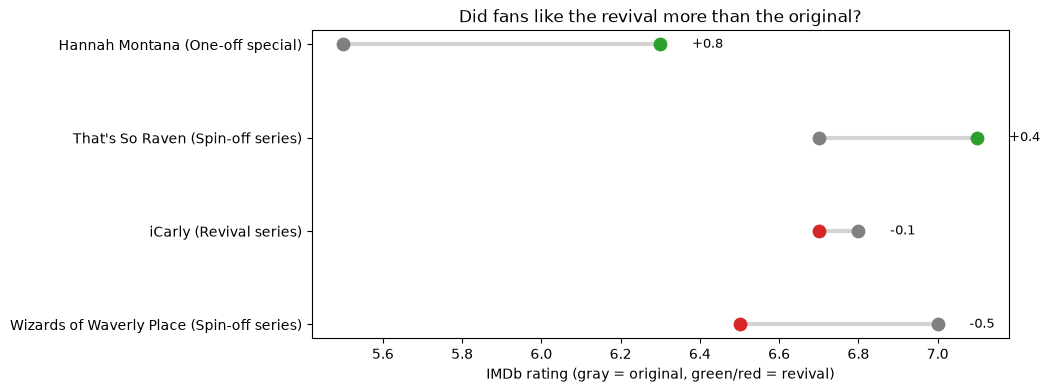

In [10]:
plot_df = compare[compare["reliable"]].sort_values("change")

fig, ax = plt.subplots(figsize=(9, 4))
for i, row in enumerate(plot_df.itertuples()):
    color = "tab:green" if row.change > 0 else "tab:red"
    ax.plot([row.original_rating, row.revival_rating], [i, i], color="lightgray", linewidth=3, zorder=1)
    ax.scatter(row.original_rating, i, color="gray", s=80, zorder=2)
    ax.scatter(row.revival_rating, i, color=color, s=80, zorder=3)
    ax.text(max(row.original_rating, row.revival_rating) + 0.08, i, f"{row.change:+.1f}", va="center", fontsize=9)

ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df["show"] + " (" + plot_df["format"] + ")")
ax.set_xlabel("IMDb rating (gray = original, green/red = revival)")
ax.set_title("Did fans like the revival more than the original?")
plt.savefig("charts/ratings_original_vs_revival.png", dpi=200, bbox_inches="tight")
plt.show()

In [11]:
import glob, os
os.makedirs("data/clean", exist_ok=True)
os.makedirs("charts", exist_ok=True)

# 1. Load every single-show Trends file into one table
frames = []
for path in sorted(glob.glob("data/raw/trends_*.csv")):
    df = pd.read_csv(path, parse_dates=["Time"]).set_index("Time")
    frames.append(df)
all_trends = pd.concat(frames, axis=1)
print("Shows loaded:", list(all_trends.columns))

events = pd.read_csv("data/raw/revival_events.csv", parse_dates=["event_date"])
missing = set(events["original_show"]) - set(all_trends.columns)
print("Missing shows:", missing or "none")

# 2. Lift and fade for every event
rows = []
for e in events.itertuples():
    s = all_trends[e.original_show]
    d = e.event_date.to_period("M").to_timestamp()
    baseline = s[d - pd.DateOffset(months=12) : d - pd.DateOffset(months=1)].median()
    window = s[d - pd.DateOffset(months=2) : d + pd.DateOffset(months=2)]
    peak, peak_month = window.max(), window.idxmax()
    after = s[peak_month:]
    back = after[after <= baseline * 1.5]
    fade = (back.index[0].to_period("M") - peak_month.to_period("M")).n if len(back) else None
    rows.append({
        "event": e.event, "format": e.format, "audience": e.original_audience,
        "studio": e.studio_family, "baseline": baseline, "peak": peak,
        "peak_month": peak_month.strftime("%Y-%m"),
        "lift": round(peak / baseline, 1), "months_to_fade": fade,
    })

lift14 = pd.DataFrame(rows).sort_values("lift", ascending=False)
lift14.to_csv("data/clean/revival_lift_14.csv", index=False)
lift14

Shows loaded: ['Boy Meets World', 'Friends', 'Full House', 'Gilmore Girls', 'Gossip Girl', 'Hannah Montana', 'iCarly', 'Lizzie McGuire', 'The Proud Family', 'Saved by the Bell', "That '70s Show", "That's So Raven", 'Wizards of Waverly Place', 'Zoey 101']
Missing shows: none


,event,format,audience,studio,baseline,peak,peak_month,lift,months_to_fade
0,Hannah Montana 20th Anniversary Special,One-off special,Kids/teen,Disney,4.0,43,2026-03,10.8,2
5,The Proud Family: Louder and Prouder,Revival series,Kids/teen,Disney,14.5,100,2022-02,6.9,3
3,Gilmore Girls: A Year in the Life,Limited revival,Teen/adult,Warner Bros.,17.5,100,2016-11,5.7,3
4,iCarly (revival),Revival series,Kids/teen,Nickelodeon/Paramount,18.0,92,2021-06,5.1,2
12,That '90s Show,Spin-off series,Teen/adult,Carsey-Werner,22.0,100,2023-01,4.5,2
13,Lizzie McGuire revival (announced; cancelled),Announced but cancelled,Kids/teen,Disney,12.0,52,2019-08,4.3,10
6,Saved by the Bell (revival),Revival series,Kids/teen,NBCUniversal,12.0,47,2020-12,3.9,3
7,Fuller House,Revival series,Family,Warner Bros.,27.5,100,2016-02,3.6,2
8,Gossip Girl (reboot),Reboot series,Teen,Warner Bros.,9.0,26,2021-07,2.9,2
10,Wizards Beyond Waverly Place,Spin-off series,Kids/teen,Disney,9.5,28,2024-11,2.9,1


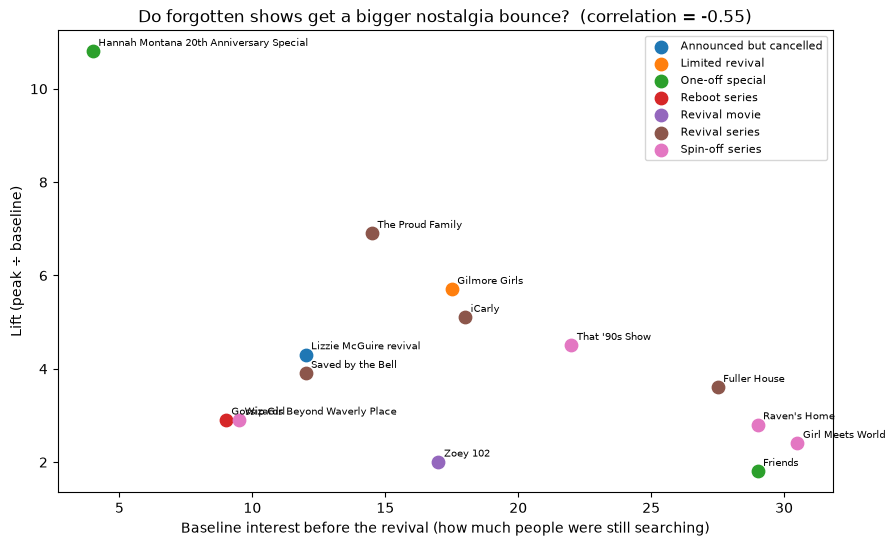

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))
for fmt, group in lift14.groupby("format"):
    ax.scatter(group["baseline"], group["lift"], s=80, label=fmt)

for row in lift14.itertuples():
    ax.annotate(row.event.split(":")[0].split(" (")[0], (row.baseline, row.lift),
                fontsize=7, xytext=(4, 4), textcoords="offset points")

corr = lift14["baseline"].corr(lift14["lift"])
ax.set_xlabel("Baseline interest before the revival (how much people were still searching)")
ax.set_ylabel("Lift (peak ÷ baseline)")
ax.set_title(f"Do forgotten shows get a bigger nostalgia bounce?  (correlation = {corr:.2f})")
ax.legend(fontsize=8)
plt.savefig("charts/lift_vs_baseline.png", dpi=200, bbox_inches="tight")
plt.show()

In [13]:
without_hannah = lift14[~lift14["event"].str.contains("Hannah")]
print("Correlation with Hannah:   ", round(lift14["baseline"].corr(lift14["lift"]), 2))
print("Correlation without Hannah:", round(without_hannah["baseline"].corr(without_hannah["lift"]), 2))

Correlation with Hannah:    -0.55
Correlation without Hannah: -0.33


In [14]:
by_format = (lift14.groupby("format")
             .agg(events=("event", "count"),
                  avg_lift=("lift", "mean"),
                  median_lift=("lift", "median"),
                  avg_months_to_fade=("months_to_fade", "mean"))
             .round(1)
             .sort_values("median_lift", ascending=False))
by_format

,events,avg_lift,median_lift,avg_months_to_fade
format,,,,
One-off special,2,6.3,6.3,2.0
Limited revival,1,5.7,5.7,3.0
Revival series,4,4.9,4.5,2.5
Announced but cancelled,1,4.3,4.3,10.0
Reboot series,1,2.9,2.9,2.0
Spin-off series,4,3.2,2.8,1.8
Revival movie,1,2.0,2.0,2.0


In [15]:
bucket_map = {
    "One-off special": "One-time event",
    "Limited revival": "One-time event",
    "Revival movie": "One-time event",
    "Revival series": "Revival series",
    "Reboot series": "Revival series",
    "Spin-off series": "Spin-off series",
}
lift14["format_group"] = lift14["format"].map(bucket_map)

aired = lift14[lift14["format_group"].notna()]
by_group = (aired.groupby("format_group")
            .agg(events=("event", "count"),
                 median_lift=("lift", "median"),
                 min_lift=("lift", "min"),
                 max_lift=("lift", "max"))
            .sort_values("median_lift", ascending=False))
by_group

,events,median_lift,min_lift,max_lift
format_group,,,,
Revival series,5,3.90,2.9,6.9
One-time event,4,3.85,1.8,10.8
Spin-off series,4,2.85,2.4,4.5


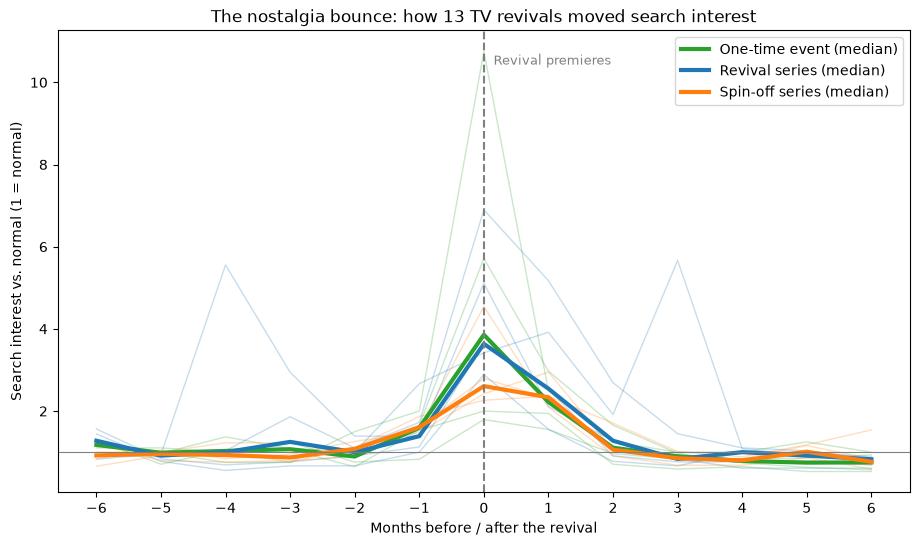

In [16]:
bucket_map = {
    "One-off special": "One-time event", "Limited revival": "One-time event",
    "Revival movie": "One-time event", "Revival series": "Revival series",
    "Reboot series": "Revival series", "Spin-off series": "Spin-off series",
}
events["format_group"] = events["format"].map(bucket_map)

curves = []
for e in events.dropna(subset=["format_group"]).itertuples():
    s = all_trends[e.original_show]
    d = e.event_date.to_period("M").to_timestamp()
    baseline = s[d - pd.DateOffset(months=12) : d - pd.DateOffset(months=1)].median()
    for m in range(-6, 7):
        month = d + pd.DateOffset(months=m)
        if month in s.index:
            curves.append({"event": e.event, "format_group": e.format_group,
                           "month": m, "x_normal": s[month] / baseline})
curves = pd.DataFrame(curves)
curves.to_csv("data/clean/event_study_curves.csv", index=False)

colors = {"One-time event": "tab:green", "Revival series": "tab:blue", "Spin-off series": "tab:orange"}
fig, ax = plt.subplots(figsize=(11, 6))
for (event, group), c in curves.groupby(["event", "format_group"]):
    ax.plot(c["month"], c["x_normal"], color=colors[group], alpha=0.25, linewidth=1)
for group, c in curves.groupby("format_group"):
    med = c.groupby("month")["x_normal"].median()
    ax.plot(med.index, med.values, color=colors[group], linewidth=3, label=f"{group} (median)")

ax.axvline(0, color="gray", linestyle="--")
ax.axhline(1, color="gray", linewidth=0.8)
ax.text(0.15, ax.get_ylim()[1] * 0.95, "Revival premieres", color="gray", fontsize=9, va="top")
ax.set_xticks(range(-6, 7))
ax.set_xlabel("Months before / after the revival")
ax.set_ylabel("Search interest vs. normal (1 = normal)")
ax.set_title("The nostalgia bounce: how 13 TV revivals moved search interest")
ax.legend()
plt.savefig("charts/hero_event_study.png", dpi=200, bbox_inches="tight")
plt.show()

In [17]:
pairs = pd.DataFrame([
    # original_show,              original IMDb title,        year, revival IMDb title,                         year
    ("Hannah Montana",           "Hannah Montana",            2006, "Hannah Montana 20th Anniversary Special",   2026),
    ("Friends",                  "Friends",                   1994, "Friends: The Reunion",                      2021),
    ("Zoey 101",                 "Zoey 101",                  2005, "Zoey 102",                                  2023),
    ("Gilmore Girls",            "Gilmore Girls",             2000, "Gilmore Girls: A Year in the Life",         2016),
    ("iCarly",                   "iCarly",                    2007, "iCarly",                                    2021),
    ("The Proud Family",         "The Proud Family",          2001, "The Proud Family: Louder and Prouder",      2022),
    ("Saved by the Bell",        "Saved by the Bell",         1989, "Saved by the Bell",                         2020),
    ("Full House",               "Full House",                1987, "Fuller House",                              2016),
    ("Gossip Girl",              "Gossip Girl",               2007, "Gossip Girl",                               2021),
    ("That's So Raven",          "That's So Raven",           2003, "Raven's Home",                              2017),
    ("Wizards of Waverly Place", "Wizards of Waverly Place",  2007, "Wizards Beyond Waverly Place",              2024),
    ("Boy Meets World",          "Boy Meets World",           1993, "Girl Meets World",                          2014),
    ("That '70s Show",           "That '70s Show",            1998, "That '90s Show",                            2023),
    ("Lizzie McGuire",           "Lizzie McGuire",            2001, "Lizzie McGuire",                            2020),
], columns=["original_show", "orig_title", "orig_year", "rev_title", "rev_year"])

# 1. SQL: pull every matching title + rating from IMDb in one query
titles = set(pairs["orig_title"]) | set(pairs["rev_title"])
title_list = ", ".join("'" + t.replace("'", "''") + "'" for t in titles)

imdb = con.sql(rf"""
    SELECT b.primaryTitle, b.titleType, TRY_CAST(b.startYear AS INTEGER) AS startYear,
           r.averageRating, r.numVotes
    FROM read_csv('data/raw/title.basics.tsv.gz',
                  delim='\t', header=true, quote='', nullstr='\N', all_varchar=true) AS b
    LEFT JOIN read_csv('data/raw/title.ratings.tsv.gz',
                  delim='\t', header=true, quote='', nullstr='\N') AS r
        USING (tconst)
    WHERE b.primaryTitle IN ({title_list})
      AND b.titleType IN ('tvSeries', 'tvMiniSeries', 'tvSpecial', 'tvMovie', 'movie')
""").df()

# 2. Match each title + year (allowing +/- 1 year), keeping the entry with the most votes
def lookup(title, year):
    m = imdb[(imdb["primaryTitle"] == title) & ((imdb["startYear"] - year).abs() <= 1)]
    m = m.sort_values("numVotes", ascending=False)
    return m.iloc[0] if len(m) else None

rows = []
for p in pairs.itertuples():
    o, r = lookup(p.orig_title, p.orig_year), lookup(p.rev_title, p.rev_year)
    if o is None or r is None:
        print("Not found on IMDb:", p.orig_title if o is None else p.rev_title)
        continue
    rows.append({"original_show": p.original_show, "revival": p.rev_title,
                 "original_rating": o["averageRating"], "revival_rating": r["averageRating"],
                 "revival_votes": int(r["numVotes"]) if pd.notna(r["numVotes"]) else 0})

ratings14 = pd.DataFrame(rows).merge(events[["original_show", "format"]], on="original_show")
ratings14["format_group"] = ratings14["format"].map(bucket_map)
ratings14["change"] = (ratings14["revival_rating"] - ratings14["original_rating"]).round(1)
ratings14["reliable"] = ratings14["revival_votes"] >= 500
ratings14 = ratings14.sort_values("change", ascending=False)
ratings14.to_csv("data/clean/ratings_original_vs_revival_14.csv", index=False)
ratings14

,original_show,revival,original_rating,revival_rating,revival_votes,format,format_group,change,reliable
0,Hannah Montana,Hannah Montana 20th Anniversary Special,5.5,6.3,1974,One-off special,One-time event,0.8,True
13,Lizzie McGuire,Lizzie McGuire,6.6,7.4,63,Announced but cancelled,NaN,0.8,False
9,That's So Raven,Raven's Home,6.7,7.1,4386,Spin-off series,Spin-off series,0.4,True
4,iCarly,iCarly,6.8,6.7,6900,Revival series,Revival series,-0.1,True
7,Full House,Fuller House,6.8,6.7,31682,Revival series,Revival series,-0.1,True
10,Wizards of Waverly Place,Wizards Beyond Waverly Place,7.0,6.5,2421,Spin-off series,Spin-off series,-0.5,True
1,Friends,Friends: The Reunion,8.8,8.0,69185,One-off special,One-time event,-0.8,True
3,Gilmore Girls,Gilmore Girls: A Year in the Life,8.2,7.4,51156,Limited revival,One-time event,-0.8,True
11,Boy Meets World,Girl Meets World,8.1,7.0,18357,Spin-off series,Spin-off series,-1.1,True
2,Zoey 101,Zoey 102,6.3,4.9,2686,Revival movie,One-time event,-1.4,True


In [18]:
print("Shows found:", len(ratings14), "of 14")
ratings14[["original_show", "original_rating", "revival_rating", "change", "revival_votes", "reliable"]]

Shows found: 14 of 14


,original_show,original_rating,revival_rating,change,revival_votes,reliable
0,Hannah Montana,5.5,6.3,0.8,1974,True
13,Lizzie McGuire,6.6,7.4,0.8,63,False
9,That's So Raven,6.7,7.1,0.4,4386,True
4,iCarly,6.8,6.7,-0.1,6900,True
7,Full House,6.8,6.7,-0.1,31682,True
10,Wizards of Waverly Place,7.0,6.5,-0.5,2421,True
1,Friends,8.8,8.0,-0.8,69185,True
3,Gilmore Girls,8.2,7.4,-0.8,51156,True
11,Boy Meets World,8.1,7.0,-1.1,18357,True
2,Zoey 101,6.3,4.9,-1.4,2686,True


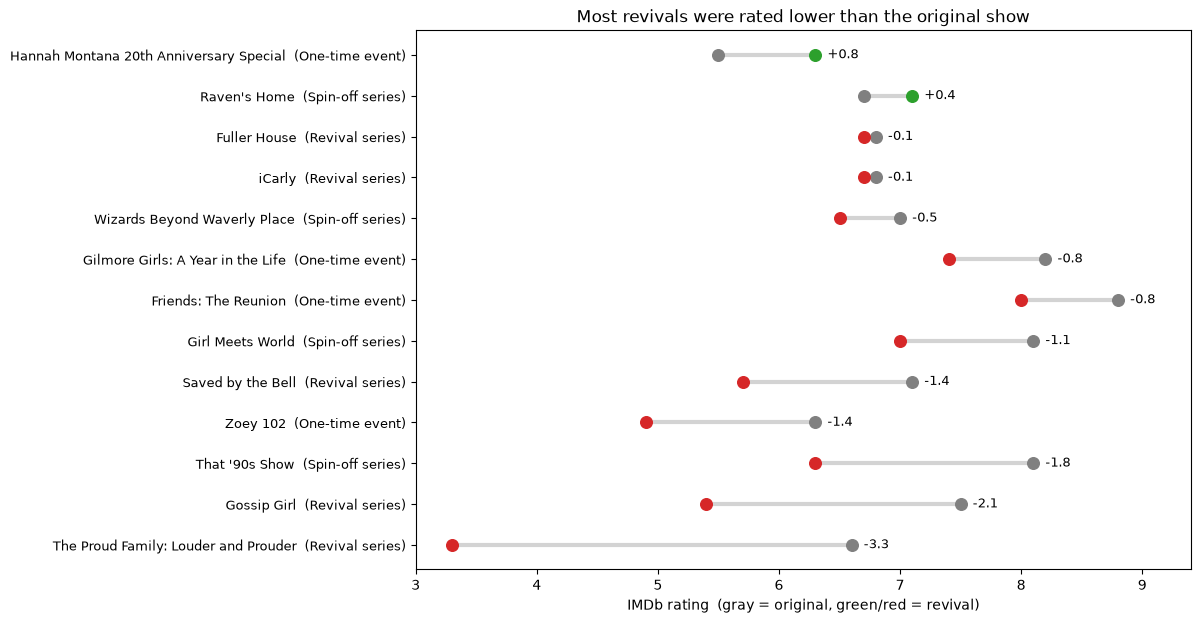

In [19]:
plot_df = ratings14[ratings14["reliable"]].sort_values("change")

fig, ax = plt.subplots(figsize=(10, 7))
for i, row in enumerate(plot_df.itertuples()):
    color = "tab:green" if row.change > 0 else "tab:red"
    ax.plot([row.original_rating, row.revival_rating], [i, i], color="lightgray", linewidth=3, zorder=1)
    ax.scatter(row.original_rating, i, color="gray", s=70, zorder=2)
    ax.scatter(row.revival_rating, i, color=color, s=70, zorder=3)
    ax.text(max(row.original_rating, row.revival_rating) + 0.1, i, f"{row.change:+.1f}", va="center", fontsize=9)

ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df["revival"] + "  (" + plot_df["format_group"] + ")", fontsize=9)
ax.set_xlim(plot_df[["original_rating", "revival_rating"]].min().min() - 0.3,
            plot_df[["original_rating", "revival_rating"]].max().max() + 0.6)
ax.set_xlabel("IMDb rating  (gray = original, green/red = revival)")
ax.set_title("Most revivals were rated lower than the original show")
plt.savefig("charts/ratings_original_vs_revival.png", dpi=200, bbox_inches="tight")
plt.show()

In [1]:
import os
from dotenv import load_dotenv
from googleapiclient.discovery import build

load_dotenv()
api_key = os.getenv("YOUTUBE_API_KEY")
print("Key loaded:", api_key is not None)

youtube = build("youtube", "v3", developerKey=api_key)
test = youtube.search().list(q="Hannah Montana 20th Anniversary Special trailer",
                             part="snippet", type="video", maxResults=3).execute()
for item in test["items"]:
    print(item["snippet"]["title"], "|", item["id"]["videoId"])

Key loaded: True
Hannah Montana 20th Anniversary Special | Official Trailer | Disney+ UK | dK2rhrwfaEo
Hannah Montana - The Best Of Both Worlds (From The Hannah Montana 20th Anniversary Special)  Disney+ | 9ItGerEKsRw
Hannah Montana 20th Anniversary Special - Official Trailer (2026) Miley Cyrus | rIDtKk9ODJA


In [2]:
import pandas as pd

trailer_searches = {
    "Hannah Montana 20th Anniversary Special": "Hannah Montana 20th Anniversary Special official trailer",
    "Friends: The Reunion": "Friends The Reunion official trailer HBO Max",
    "Zoey 102": "Zoey 102 official trailer Paramount+",
    "Gilmore Girls: A Year in the Life": "Gilmore Girls A Year in the Life official trailer Netflix",
    "iCarly (revival)": "iCarly revival official trailer Paramount+ 2021",
    "The Proud Family: Louder and Prouder": "The Proud Family Louder and Prouder official trailer",
    "Saved by the Bell (revival)": "Saved by the Bell Peacock official trailer 2020",
    "Fuller House": "Fuller House official trailer Netflix",
    "Gossip Girl (reboot)": "Gossip Girl HBO Max official trailer 2021",
    "Raven's Home": "Raven's Home official trailer Disney Channel",
    "Wizards Beyond Waverly Place": "Wizards Beyond Waverly Place official trailer",
    "Girl Meets World": "Girl Meets World official trailer Disney Channel",
    "That '90s Show": "That '90s Show official trailer Netflix",
}

rows = []
for event, query in trailer_searches.items():
    res = youtube.search().list(q=query, part="snippet", type="video", maxResults=3).execute()
    for rank, item in enumerate(res["items"], start=1):
        rows.append({
            "event": event,
            "rank": rank,
            "title": item["snippet"]["title"],
            "channel": item["snippet"]["channelTitle"],
            "published": item["snippet"]["publishedAt"][:10],
            "video_id": item["id"]["videoId"],
        })

candidates = pd.DataFrame(rows)
candidates.to_csv("data/raw/trailer_candidates.csv", index=False)
pd.set_option("display.max_colwidth", 70)
candidates

,event,rank,title,channel,published,video_id
0,Hannah Montana 20th Anniversary Special,1,The Hannah Montana reunion felt... Off,Aggressively Average,2026-03-24,ZswxYBJA_gg
1,Hannah Montana 20th Anniversary Special,2,Miley Cyrus - Younger You (From the &quot;Hannah Montana 20th Anni...,MileyCyrusVEVO,2026-03-27,s-dr_KJvmO4
2,Hannah Montana 20th Anniversary Special,3,Hannah Montana 20th Anniversary | Home | Disney+ Singapore,Disney+ Singapore,2026-03-24,o6nypbftPfw
3,Friends: The Reunion,1,Friends: The Reunion Trailer | Rotten Tomatoes TV,Rotten Tomatoes TV,2021-05-19,RasWhgd4vao
4,Friends: The Reunion,2,Friends: The Reunion - Official Teaser Trailer (2021) HBO Max,IGN,2021-05-13,VvKlM51Rgeo
5,Friends: The Reunion,3,FRIENDS: THE REUNION Official Trailer,ONE Media,2021-05-19,LTpmw0Ac6Zs
6,Zoey 102,1,Zoey 102 | Official Trailer | Paramount+,Paramount Plus,2023-06-20,2a3VKZyu_0g
7,Zoey 102,2,Zoey 102 | Official Trailer 2 | Paramount+,Paramount Plus,2023-07-21,wiyYE1G6n-M
8,Zoey 102,3,Zoey 102 | Sneak Peek | Paramount+,Paramount Plus,2023-07-27,d902SUiBzrQ
9,Gilmore Girls: A Year in the Life,1,Gilmore Girls: A Year in the Life | Main Trailer [HD] | Netflix,Netflix India,2016-10-25,VBK6ciLtd1I


In [3]:
retry = {
    "Hannah Montana 20th Anniversary Special": ("Hannah Montana 20th Anniversary Special official trailer", ["Disney Plus", "Disney Channel", "Disney+"]),
    "Friends: The Reunion": ("Friends The Reunion official trailer", ["HBO Max", "Max", "HBO"]),
    "Fuller House": ("Fuller House season 1 official trailer Netflix", ["Netflix"]),
    "Gossip Girl (reboot)": ("Gossip Girl 2021 official trailer HBO Max", ["HBO Max", "Max", "HBO"]),
    "That '90s Show": ("That '90s Show season 1 official trailer Netflix", ["Netflix"]),
}

for event, (query, channels) in retry.items():
    res = youtube.search().list(q=query, part="snippet", type="video", maxResults=15).execute()
    print(f"\n=== {event} ===")
    found = False
    for item in res["items"]:
        ch = item["snippet"]["channelTitle"]
        if ch in channels:
            found = True
            print(f"  [{ch}]  {item['snippet']['title'][:65]}  ({item['snippet']['publishedAt'][:10]})  id={item['id']['videoId']}")
    if not found:
        print("  No official-channel results found")


=== Hannah Montana 20th Anniversary Special ===
  [Disney Plus]  Hannah Montana 20th Anniversary Special Teaser  (2026-02-20)  id=y2_VVUoHiAU

=== Friends: The Reunion ===
  [HBO Max]  Phoebe Finds Out | Friends: The Reunion | Max  (2021-05-29)  id=vtpK-D-5FCs

=== Fuller House ===
  [Netflix]  Farewell Season: Fuller House | Official Trailer | Netflix  (2020-05-12)  id=PG1gU7fjBUk
  [Netflix]  Fuller House | Teaser [HD] | Netflix  (2016-01-15)  id=N9y61eSRPM8
  [Netflix]  Fuller House - Season 3 | Official Trailer [HD] | Netflix  (2017-09-15)  id=446dbFQEFJU
  [Netflix]  Fuller House: Season 4 | Official Trailer [HD] | Netflix  (2018-11-27)  id=66N2TTDD8X8
  [Netflix]  Fuller House Season 5 - PART A | Official Trailer | Netflix  (2019-11-23)  id=dFSkS2WeClo
  [Netflix]  Fuller House | Featurette [HD] | Netflix  (2016-01-26)  id=I3EVwJSqd64

=== Gossip Girl (reboot) ===
  No official-channel results found

=== That '90s Show ===
  [Netflix]  That &#39;90s Show | Part 3 Official Traile

In [4]:
final_retry = {
    "Friends: The Reunion": "Friends: The Reunion Official Trailer HBO Max May 2021",
    "Gossip Girl (reboot)": "Gossip Girl Official Trailer HBO Max July 2021",
    "That '90s Show": "That '90s Show Official Trailer Netflix December 2022",
}

for event, query in final_retry.items():
    res = youtube.search().list(q=query, part="snippet", type="video", maxResults=10,
                                publishedBefore="2023-01-20T00:00:00Z").execute()
    print(f"\n=== {event} ===")
    for item in res["items"]:
        print(f"  [{item['snippet']['channelTitle']}]  {item['snippet']['title'][:60]}  "
              f"({item['snippet']['publishedAt'][:10]})  id={item['id']['videoId']}")


=== Friends: The Reunion ===
  [Rotten Tomatoes TV]  Friends: The Reunion Trailer | Rotten Tomatoes TV  (2021-05-19)  id=RasWhgd4vao
  [IGN]  Friends: The Reunion - Official Teaser Trailer (2021) HBO Ma  (2021-05-13)  id=VvKlM51Rgeo
  [ONE Media]  FRIENDS: THE REUNION Official Trailer  (2021-05-19)  id=LTpmw0Ac6Zs
  [Los Chulos Team]  Friends - The Reunion (2021) | HBO MAX | Trailer Oficial Leg  (2021-05-19)  id=L0B72IK-8oU
  [KinoCheck.com]  FRIENDS: The Reunion Trailer (2021)  (2021-05-19)  id=Ms_GK9LLtw8
  [HBO Max]  Phoebe Finds Out | Friends: The Reunion | Max  (2021-05-29)  id=vtpK-D-5FCs
  [EMSquare]  Friends: The Reunion | Official Trailer | HBO Max  (2021-05-20)  id=LLm3iLCWXVQ
  [IGN Movie Trailers]  Friends: The Reunion - Official Teaser Trailer (2021) HBO Ma  (2021-05-13)  id=b1fT7JuelHs
  [HBO Max Brasil]  Friends: The Reunion | Trailer Oficial  (2021-05-19)  id=wtZrQzzlqi4
  [Rutafos]  FRIENDS: THE REUNION - Final Trailer (2021) HBO  (2021-05-19)  id=SmRglRRqRko

=== Gos

In [5]:
trailers = pd.DataFrame([
    ("Hannah Montana 20th Anniversary Special", "y2_VVUoHiAU", "official"),
    ("Friends: The Reunion",                    "RasWhgd4vao", "re-upload"),
    ("Zoey 102",                                "2a3VKZyu_0g", "official"),
    ("Gilmore Girls: A Year in the Life",       "VBK6ciLtd1I", "official"),
    ("iCarly (revival)",                        "7NKVThOGLXc", "official"),
    ("The Proud Family: Louder and Prouder",    "qNlrmBWY25Q", "official"),
    ("Saved by the Bell (revival)",             "O0uCr5-5p5Q", "official"),
    ("Fuller House",                            "N9y61eSRPM8", "official"),
    ("Gossip Girl (reboot)",                    "ai5hin7ffs0", "re-upload"),
    ("Raven's Home",                            "uZrjvwPeKIM", "official"),
    ("Wizards Beyond Waverly Place",            "M_3dQ6ofXwI", "official"),
    ("Girl Meets World",                        "EYZhGgc63II", "official"),
    ("That '90s Show",                          "YM6ZkmRZRJs", "re-upload"),
], columns=["event", "video_id", "source_type"])

info = youtube.videos().list(part="snippet,statistics", id=",".join(trailers["video_id"])).execute()
stats = {v["id"]: {"channel": v["snippet"]["channelTitle"],
                   "views": int(v["statistics"].get("viewCount", 0)),
                   "comments": int(v["statistics"]["commentCount"]) if "commentCount" in v["statistics"] else None}
         for v in info["items"]}

trailers["channel"] = trailers["video_id"].map(lambda i: stats.get(i, {}).get("channel"))
trailers["views"] = trailers["video_id"].map(lambda i: stats.get(i, {}).get("views"))
trailers["comments"] = trailers["video_id"].map(lambda i: stats.get(i, {}).get("comments"))
trailers.to_csv("data/raw/trailers.csv", index=False)
trailers

,event,video_id,source_type,channel,views,comments
0,Hannah Montana 20th Anniversary Special,y2_VVUoHiAU,official,Disney Plus,162395,125
1,Friends: The Reunion,RasWhgd4vao,re-upload,Rotten Tomatoes TV,1471596,595
2,Zoey 102,2a3VKZyu_0g,official,Paramount Plus,7160180,2659
3,Gilmore Girls: A Year in the Life,VBK6ciLtd1I,official,Netflix India,730918,216
4,iCarly (revival),7NKVThOGLXc,official,Paramount Plus,4792098,11498
5,The Proud Family: Louder and Prouder,qNlrmBWY25Q,official,Disney Plus,5548291,0
6,Saved by the Bell (revival),O0uCr5-5p5Q,official,Peacock,2184884,1672
7,Fuller House,N9y61eSRPM8,official,Netflix,5749777,2890
8,Gossip Girl (reboot),ai5hin7ffs0,re-upload,Rotten Tomatoes TV,91572,14
9,Raven's Home,uZrjvwPeKIM,official,Disney Channel,3521555,0


In [6]:
alternatives = {
    "Wizards Beyond (Disney Plus)":    "BtCBanGregI",
    "Raven's Home (Disney UK)":        "9D0BB1Ik_Ns",
    "Gossip Girl (TV Promos)":         "XhsV1gPVJMQ",
    "Gossip Girl (KinoCheck)":         "dS3hDAORTVk",
    "Girl Meets World (Coming Soon)":  "KVrSUEEPubs",
}

info = youtube.videos().list(part="snippet,statistics", id=",".join(alternatives.values())).execute()
for v in info["items"]:
    print(f"{v['snippet']['channelTitle']:<20} {v['snippet']['publishedAt'][:10]}  "
          f"comments={v['statistics'].get('commentCount', 'OFF'):<8} {v['snippet']['title'][:50]}  id={v['id']}")

Disney Plus          2024-09-24  comments=1932     Official Trailer | Wizards Beyond Waverly Place |   id=BtCBanGregI
Disney Club UK       2017-06-28  comments=0        Raven's Home | Official Trailer | Official Disney   id=9D0BB1Ik_Ns
TV Promos            2021-06-10  comments=4324     Gossip Girl (HBO Max) Trailer HD  id=XhsV1gPVJMQ
KinoCheck.com        2021-06-14  comments=196      GOSSIP GIRL Trailer (2021)  id=dS3hDAORTVk
Disney Channel       2014-04-11  comments=0        Coming Soon - Girl Meets World - Disney Channel Of  id=KVrSUEEPubs


In [7]:
trailers.loc[trailers["event"] == "Wizards Beyond Waverly Place", ["video_id", "channel"]] = ["BtCBanGregI", "Disney Plus"]
trailers.loc[trailers["event"] == "Gossip Girl (reboot)", ["video_id", "channel"]] = ["XhsV1gPVJMQ", "TV Promos"]

no_comments = ["The Proud Family: Louder and Prouder", "Raven's Home", "Girl Meets World"]
trailers["usable"] = ~trailers["event"].isin(no_comments)

trailers.to_csv("data/raw/trailers.csv", index=False)
trailers[["event", "video_id", "channel", "source_type", "usable"]]

,event,video_id,channel,source_type,usable
0,Hannah Montana 20th Anniversary Special,y2_VVUoHiAU,Disney Plus,official,True
1,Friends: The Reunion,RasWhgd4vao,Rotten Tomatoes TV,re-upload,True
2,Zoey 102,2a3VKZyu_0g,Paramount Plus,official,True
3,Gilmore Girls: A Year in the Life,VBK6ciLtd1I,Netflix India,official,True
4,iCarly (revival),7NKVThOGLXc,Paramount Plus,official,True
5,The Proud Family: Louder and Prouder,qNlrmBWY25Q,Disney Plus,official,False
6,Saved by the Bell (revival),O0uCr5-5p5Q,Peacock,official,True
7,Fuller House,N9y61eSRPM8,Netflix,official,True
8,Gossip Girl (reboot),XhsV1gPVJMQ,TV Promos,re-upload,True
9,Raven's Home,uZrjvwPeKIM,Disney Channel,official,False


In [ ]:
from googleapiclient.errors import HttpError

def get_comments(video_id):
    comments, page_token = [], None
    while True:
        res = youtube.commentThreads().list(
            part="snippet", videoId=video_id, maxResults=100,
            textFormat="plainText", pageToken=page_token
        ).execute()
        for item in res["items"]:
            c = item["snippet"]["topLevelComment"]["snippet"]
            comments.append({
                "video_id": video_id,
                "text": c["textOriginal"],
                "likes": c["likeCount"],
                "published": c["publishedAt"][:10],
            })
        page_token = res.get("nextPageToken")
        if not page_token:
            return comments

all_comments = []
for t in trailers[trailers["usable"]].itertuples():
    try:
        got = get_comments(t.video_id)
        for c in got:
            c["event"] = t.event
        all_comments.extend(got)
        print(f"{t.event:<45} {len(got):>6} comments")
    except HttpError as e:
        print(f"{t.event:<45} ERROR: {e.reason}")

comments_df = pd.DataFrame(all_comments)
comments_df.to_csv("data/raw/youtube_comments.csv", index=False)
print("\nTotal comments collected:", len(comments_df))

In [9]:
from googleapiclient.errors import HttpError

def get_comments(video_id):
    comments, page_token = [], None
    while True:
        res = youtube.commentThreads().list(
            part="snippet", videoId=video_id, maxResults=100,
            textFormat="plainText", pageToken=page_token
        ).execute()
        for item in res["items"]:
            c = item["snippet"]["topLevelComment"]["snippet"]
            comments.append({
                "video_id": video_id,
                "text": c["textOriginal"],
                "likes": c["likeCount"],
                "published": c["publishedAt"][:10],
            })
        page_token = res.get("nextPageToken")
        if not page_token:
            return comments

all_comments = []
for t in trailers[trailers["usable"]].itertuples():
    try:
        got = get_comments(t.video_id)
        for c in got:
            c["event"] = t.event
        all_comments.extend(got)
        print(f"{t.event:<45} {len(got):>6} comments")
    except HttpError as e:
        print(f"{t.event:<45} ERROR: {e.reason}")

comments_df = pd.DataFrame(all_comments)
comments_df.to_csv("data/raw/youtube_comments.csv", index=False)
print("\nTotal comments collected:", len(comments_df))

Hannah Montana 20th Anniversary Special          100 comments
Friends: The Reunion                             475 comments
Zoey 102                                        1754 comments
Gilmore Girls: A Year in the Life                105 comments
iCarly (revival)                                7400 comments
Saved by the Bell (revival)                     1093 comments
Fuller House                                    1842 comments
Gossip Girl (reboot)                            2777 comments
Wizards Beyond Waverly Place                    1087 comments
That '90s Show                                   457 comments

Total comments collected: 17090


In [10]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import re

analyzer = SentimentIntensityAnalyzer()

# 1. Sentiment: -1 (very negative) to +1 (very positive)
comments_df["sentiment"] = comments_df["text"].astype(str).map(lambda t: analyzer.polarity_scores(t)["compound"])
comments_df["label"] = pd.cut(comments_df["sentiment"], [-1.01, -0.05, 0.05, 1.01],
                              labels=["negative", "neutral", "positive"])

# 2. Nostalgia: does the comment use nostalgic language?
nostalgia_words = r"childhood|grew up|growing up|nostalgi|memories|brings me back|takes me back|" \
                  r"when i was (a kid|little|young)|used to watch|throwback|good old days|back in the day"
comments_df["nostalgic"] = comments_df["text"].astype(str).str.lower().str.contains(nostalgia_words, regex=True)

# 3. Was the comment posted before the revival premiered?
premieres = pd.read_csv("data/raw/revival_events.csv")[["event", "event_date"]]
comments_df = comments_df.merge(premieres, on="event", how="left")
comments_df["before_premiere"] = comments_df["published"] < comments_df["event_date"]

# 4. Summary per show
summary = (comments_df.groupby("event")
           .agg(comments=("text", "count"),
                before_premiere=("before_premiere", "sum"),
                avg_sentiment=("sentiment", "mean"),
                pct_positive=("label", lambda s: (s == "positive").mean() * 100),
                pct_negative=("label", lambda s: (s == "negative").mean() * 100),
                pct_nostalgic=("nostalgic", "mean"))
           .assign(pct_nostalgic=lambda d: d["pct_nostalgic"] * 100)
           .round(2)
           .sort_values("avg_sentiment", ascending=False))
summary.to_csv("data/clean/trailer_sentiment_summary.csv")
summary

ModuleNotFoundError: No module named 'vaderSentiment'

In [11]:
%pip install vaderSentiment


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [12]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import re

analyzer = SentimentIntensityAnalyzer()

# 1. Sentiment: -1 (very negative) to +1 (very positive)
comments_df["sentiment"] = comments_df["text"].astype(str).map(lambda t: analyzer.polarity_scores(t)["compound"])
comments_df["label"] = pd.cut(comments_df["sentiment"], [-1.01, -0.05, 0.05, 1.01],
                              labels=["negative", "neutral", "positive"])

# 2. Nostalgia: does the comment use nostalgic language?
nostalgia_words = r"childhood|grew up|growing up|nostalgi|memories|brings me back|takes me back|" \
                  r"when i was (a kid|little|young)|used to watch|throwback|good old days|back in the day"
comments_df["nostalgic"] = comments_df["text"].astype(str).str.lower().str.contains(nostalgia_words, regex=True)

# 3. Was the comment posted before the revival premiered?
premieres = pd.read_csv("data/raw/revival_events.csv")[["event", "event_date"]]
comments_df = comments_df.merge(premieres, on="event", how="left")
comments_df["before_premiere"] = comments_df["published"] < comments_df["event_date"]

# 4. Summary per show
summary = (comments_df.groupby("event")
           .agg(comments=("text", "count"),
                before_premiere=("before_premiere", "sum"),
                avg_sentiment=("sentiment", "mean"),
                pct_positive=("label", lambda s: (s == "positive").mean() * 100),
                pct_negative=("label", lambda s: (s == "negative").mean() * 100),
                pct_nostalgic=("nostalgic", "mean"))
           .assign(pct_nostalgic=lambda d: d["pct_nostalgic"] * 100)
           .round(2)
           .sort_values("avg_sentiment", ascending=False))
summary.to_csv("data/clean/trailer_sentiment_summary.csv")
summary

/var/folders/47/d26hr16j3p57649slptww9wm0000gn/T/ipykernel_5433/3315279894.py:14: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  comments_df["nostalgic"] = comments_df["text"].astype(str).str.lower().str.contains(nostalgia_words, regex=True)


,comments,before_premiere,avg_sentiment,pct_positive,pct_negative,pct_nostalgic
event,,,,,,
Hannah Montana 20th Anniversary Special,100,95,0.36,62.00,7.00,6.00
Wizards Beyond Waverly Place,1087,920,0.22,50.51,17.11,6.35
Friends: The Reunion,475,106,0.20,49.26,23.16,2.32
Zoey 102,1754,1293,0.18,47.15,19.90,5.30
Gilmore Girls: A Year in the Life,105,1,0.16,47.62,22.86,1.90
Gossip Girl (reboot),2777,2362,0.15,47.93,28.34,0.94
iCarly (revival),7400,6791,0.13,41.95,22.51,6.27
Saved by the Bell (revival),1093,829,0.10,38.43,25.43,2.65
That '90s Show,457,255,0.10,43.33,31.07,2.84


In [13]:
lift = pd.read_csv("data/clean/revival_lift_14.csv")[["event", "lift"]]
ratings = pd.read_csv("data/clean/ratings_original_vs_revival_14.csv")
ratings = ratings.merge(pd.read_csv("data/raw/revival_events.csv")[["original_show", "event"]],
                        on="original_show")[["event", "change"]]

combined = (summary.reset_index()
            .merge(lift, on="event")
            .merge(ratings, on="event")
            .rename(columns={"change": "imdb_change"}))
combined.to_csv("data/clean/sentiment_lift_ratings.csv", index=False)

print("Trailer sentiment vs. buzz lift:     ", round(combined["avg_sentiment"].corr(combined["lift"]), 2))
print("Trailer sentiment vs. IMDb change:   ", round(combined["avg_sentiment"].corr(combined["imdb_change"]), 2))
print("Nostalgic comments vs. buzz lift:    ", round(combined["pct_nostalgic"].corr(combined["lift"]), 2))

no_hannah = combined[~combined["event"].str.contains("Hannah")]
print("\nWithout Hannah:")
print("Trailer sentiment vs. IMDb change:   ", round(no_hannah["avg_sentiment"].corr(no_hannah["imdb_change"]), 2))

combined[["event", "avg_sentiment", "pct_nostalgic", "lift", "imdb_change"]]

Trailer sentiment vs. buzz lift:      0.58
Trailer sentiment vs. IMDb change:    0.52
Nostalgic comments vs. buzz lift:     0.32

Without Hannah:
Trailer sentiment vs. IMDb change:    -0.01


,event,avg_sentiment,pct_nostalgic,lift,imdb_change
0,Hannah Montana 20th Anniversary Special,0.36,6.00,10.8,0.8
1,Wizards Beyond Waverly Place,0.22,6.35,2.9,-0.5
2,Friends: The Reunion,0.20,2.32,1.8,-0.8
3,Zoey 102,0.18,5.30,2.0,-1.4
4,Gilmore Girls: A Year in the Life,0.16,1.90,5.7,-0.8
5,Gossip Girl (reboot),0.15,0.94,2.9,-2.1
6,iCarly (revival),0.13,6.27,5.1,-0.1
7,Saved by the Bell (revival),0.10,2.65,3.9,-1.4
8,That '90s Show,0.10,2.84,4.5,-1.8
9,Fuller House,0.06,3.26,3.6,-0.1


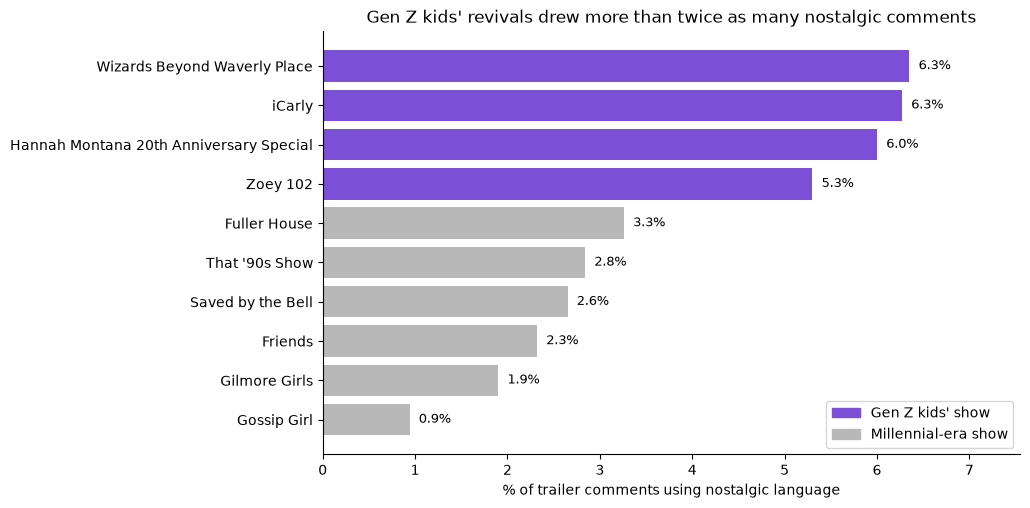

generation
Gen Z kids' show       6.0
Millennial-era show    2.3
Name: pct_nostalgic, dtype: float64


In [16]:
from matplotlib.patches import Patch

gen_z = ["Hannah Montana 20th Anniversary Special", "Wizards Beyond Waverly Place",
         "iCarly (revival)", "Zoey 102"]
combined["generation"] = combined["event"].apply(lambda e: "Gen Z kids' show" if e in gen_z else "Millennial-era show")

plot_df = combined.sort_values("pct_nostalgic")
colors = plot_df["generation"].map({"Gen Z kids' show": "#7B4FD6", "Millennial-era show": "#B8B8B8"})
labels = plot_df["event"].str.replace(r" \(.*\)", "", regex=True).str.split(":").str[0]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(labels, plot_df["pct_nostalgic"], color=colors)
for i, v in enumerate(plot_df["pct_nostalgic"]):
    ax.text(v + 0.1, i, f"{v:.1f}%", va="center", fontsize=9)

ax.set_xlabel("% of trailer comments using nostalgic language")
ax.set_title("Gen Z kids' revivals drew more than twice as many nostalgic comments")
ax.legend(handles=[Patch(color="#7B4FD6", label="Gen Z kids' show"),
                   Patch(color="#B8B8B8", label="Millennial-era show")], loc="lower right")
ax.set_xlim(0, plot_df["pct_nostalgic"].max() + 1.2)
ax.spines[["top", "right"]].set_visible(False)
plt.savefig("charts/nostalgia_comments.png", dpi=200, bbox_inches="tight")
plt.show()

print(combined.groupby("generation")["pct_nostalgic"].mean().round(1))

In [15]:
import matplotlib.pyplot as plt